# Задача 9. Модель детектора в PyMC

Модель из задач 1–3 (и затухание из задачи 6) записана как вероятностный граф в [pymc_model.py](pymc_model.py). Геометрия — координаты ФЭУ из класса `Detector` (задача 1) — входит в граф как константа, а всё, что разыгрывается при событии, — узлы графа:

| узел | распределение / формула | задача |
|---|---|---|
| `n_gamma` | $YE$ или $\mathrm{Poisson}(YE)$ | 2, 5 |
| `phi`, `cosTheta` | $U(0, 2\pi)$, $U(-1, 1)$ — изотропные направления | 2 |
| путь `t`, точка `p` | $t = -(\vec o\cdot\vec n) + \sqrt{(\vec o\cdot\vec n)^2 - o^2 + R^2}$ | 3 |
| попадание на катод | $\vec p\cdot\vec n_k > 0,\ R^2 - (\vec p\cdot\vec n_k)^2 \le r^2$ | 1, 3 |
| `u` (опционально) | $U(0,1)$, фотон выживает при $u < e^{-t/L}$ | 6 |
| `hits` | Deterministic: число фотонов на каждом катоде | 3 |
| `pe` | $\mathrm{Poisson}(a\cdot\mathrm{hits}_k)$ | 3 |
| `Q` | Deterministic: $\sum_k \mathrm{pe}_k$ | 3, 4 |

Все функции — те же формулы, что в numpy-версии, с заменой `np.*` на `pt.*` (pytensor).

**Число фотонов.** В модели задач 1–3 и в сравнении с задачей 4 оно фиксировано: $n_\gamma = YE$ (`fluctuate=False`). Пуассоновское появляется в задаче 5, и оно используется ниже при сравнении с задачей 6. Размеры массивов в графе фиксированы, а $n_\gamma$ может быть случайным. Поэтому направления разыгрываются для $n_{max} = \langle n\rangle + 7\sigma$ фотонов, а учитываются первые $n_\gamma$ (маска `emitted = arange(n_max) < n_gamma`). Вероятность $n_\gamma > n_{max}$ — порядка $10^{-12}$.

**Как получать события.** Здесь нет наблюдаемых данных — мы моделируем отклик, т.е. сэмплируем совместное распределение всех узлов. Граф направленный и ациклический, поэтому для этого не нужна MCMC: `pm.sample_prior_predictive` разыгрывает узлы по порядку (предковое сэмплирование), и каждое событие независимо. MCMC (`pm.sample`) понадобится в обратной задаче — восстановлении $E$ и вершины по наблюдённым зарядам.

In [1]:
import logging
logging.getLogger("pytensor.configdefaults").setLevel(logging.ERROR)   # нет компилятора C++, pytensor использует numba
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pymc as pm
from detector import Detector
from source import Source
from simulation import simulate_charge, expected_fraction
from pymc_model import photon_model, multinomial_model, sample_Q
logging.getLogger("pymc").setLevel(logging.ERROR)   # без сообщений о каждом запуске сэмплера

Y, E, n_events = 10_000, 1.0, 1000
det = Detector(R=2.0, N=40, r=0.10, a=0.5, rng=9)
model = photon_model(det, Y, E, fluctuate=False)
model

     phi ~ Uniform(0, 6.28)
cosTheta ~ Uniform(-1, 1)
      pe ~ Poisson(f(hits))
 n_gamma = Deterministic(<constant>)
    hits = Deterministic(f(n_gamma, cosTheta, phi))
       Q = Deterministic(f(pe))

In [2]:
# структура графа: родители каждого узла и его размерность
graph = pm.model_graph.ModelGraph(model).make_compute_graph()
for v in model.free_RVs + model.deterministics:
    kind = "Deterministic" if v in model.deterministics else type(v.owner.op).__name__.replace("RV", "")
    shape = tuple(int(x) for x in v.shape.eval())
    parents = ', '.join(sorted(graph.get(v.name, []))) or '—'
    print(f"{v.name:10s} {kind:14s} shape={str(shape):10s} родители: {parents}")

phi        Uniform        shape=(10700,)   родители: —
cosTheta   Uniform        shape=(10700,)   родители: —
pe         Poisson        shape=(40,)      родители: hits
n_gamma    Deterministic  shape=()         родители: —
hits       Deterministic  shape=(40,)      родители: cosTheta, n_gamma, phi
Q          Deterministic  shape=()         родители: pe


## Отклик детектора: E = 1 МэВ, центр

In [3]:
t = time.perf_counter()
s_pm = sample_Q(model, n_events, seed=9)
print(f"PyMC, пофотонная модель: {time.perf_counter() - t:.1f} с на {n_events} событий")

t = time.perf_counter()
Q_np = simulate_charge(det, Source(Y=Y, rng=90), E, n_events=n_events, fluctuate=False).sum(axis=1)
print(f"numpy (задача 4):        {time.perf_counter() - t:.1f} с")

Q_pm = s_pm['Q']
Q_exp = det.a * Y * E * det.coverage()
for name, Q in (("PyMC", Q_pm), ("numpy", Q_np)):
    print(f"{name:6s}: <Q> = {Q.mean():7.2f} ± {Q.std()/np.sqrt(len(Q)):.2f},  σ = {Q.std():6.2f}")
print(f"ожидание: <Q> = {Q_exp:.2f}, σ = {np.sqrt(Q_exp * (1 + det.a * (1 - det.coverage()))):.2f}")
print(f"<n_gamma> = {s_pm['n_gamma'].mean():.1f}, D = {s_pm['n_gamma'].var():.1f}")
print("KS-тест PyMC vs numpy: p =", round(stats.ks_2samp(Q_pm, Q_np).pvalue, 3))

PyMC, пофотонная модель: 1.6 с на 1000 событий


numpy (задача 4):        4.0 с
PyMC  : <Q> =  124.71 ± 0.43,  σ =  13.71
numpy : <Q> =  124.68 ± 0.42,  σ =  13.12
ожидание: <Q> = 125.08, σ = 13.64
<n_gamma> = 10000.0, D = 0.0
KS-тест PyMC vs numpy: p = 0.61


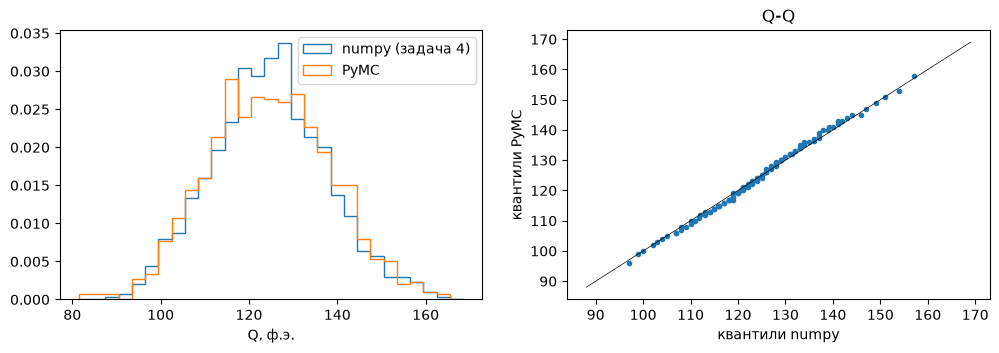

In [4]:
bins = np.arange(min(Q_pm.min(), Q_np.min()) - 0.5, max(Q_pm.max(), Q_np.max()) + 1.5, 3)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(Q_np, bins=bins, histtype='step', density=True, label='numpy (задача 4)')
ax[0].hist(Q_pm, bins=bins, histtype='step', density=True, label='PyMC')
ax[0].set_xlabel('Q, ф.э.'); ax[0].legend()
q = np.linspace(0, 1, 101)[1:-1]
ax[1].plot(np.quantile(Q_np, q), np.quantile(Q_pm, q), 'o', ms=3)
lim = [Q_np.min(), Q_np.max()]; ax[1].plot(lim, lim, 'k', lw=0.5)
ax[1].set_xlabel('квантили numpy'); ax[1].set_ylabel('квантили PyMC'); ax[1].set_title('Q-Q')
plt.show()

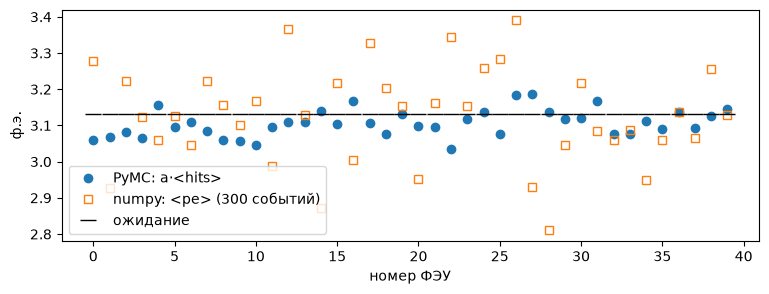

In [5]:
# распределение заряда по каналам тоже совпадает
pe_np = np.array([det.response(np.zeros(3), Source(Y=Y, rng=1000 + i).directions(E, fluctuate=False)) for i in range(300)])
plt.figure(figsize=(9, 3))
plt.plot(s_pm['hits'].mean(axis=0) * det.a, 'o', label='PyMC: a·<hits>')
plt.plot(pe_np.mean(axis=0), 's', mfc='none', label='numpy: <pe> (300 событий)')
plt.plot(det.a * Y * E * expected_fraction(det), 'k_', ms=12, label='ожидание')
plt.xlabel('номер ФЭУ'); plt.ylabel('ф.э.'); plt.legend(); plt.show()

## Компактная модель

Каждый фотон независимо попадает на катод $k$ с вероятностью $p_k$ = (телесный угол катода)/$4\pi$ или никуда не попадает. Поэтому вместо $10^4$ направлений можно сразу разыграть числа фотонов на катодах: $\mathrm{hits} \sim \mathrm{Multinomial}(n_\gamma, (p_1, \dots, p_N, 1 - \sum p_k))$ — это то же распределение. $p_k$ берём в приближении малого диска (как `expected_fraction` в задаче 4, записано через `pt.*`).

In [6]:
m_mult = multinomial_model(det, Y, E, fluctuate=False)
t = time.perf_counter()
Q_mult = sample_Q(m_mult, n_events, seed=10)['Q']
print(f"мультиномиальная модель: {time.perf_counter() - t:.1f} с")
print(f"<Q> = {Q_mult.mean():.2f} ± {Q_mult.std()/np.sqrt(n_events):.2f}, σ = {Q_mult.std():.2f}")
print("KS vs numpy: p =", round(stats.ks_2samp(Q_mult, Q_np).pvalue, 3))

мультиномиальная модель: 0.1 с
<Q> = 125.12 ± 0.43, σ = 13.61
KS vs numpy: p = 0.723


## Затухание (L = 8 м)

В пофотонную модель добавлен узел `u ~ U(0,1)` на каждый фотон: фотон доходит до стенки, если $u < e^{-t/L}$. Сравниваем с numpy-моделью задачи 6 в центре и при $z = 1.5$ м; как и там, число фотонов пуассоновское.

z = 0.0 м:  PyMC <Q> =  96.99 ± 0.38 (σ = 11.89),  numpy <Q> =  97.06 ± 0.38 (σ = 11.88),  ожидание 97.62,  KS p = 0.997


z = 1.5 м:  PyMC <Q> = 100.48 ± 0.39 (σ = 12.44),  numpy <Q> = 100.78 ± 0.40 (σ = 12.72),  ожидание 101.05,  KS p = 0.914


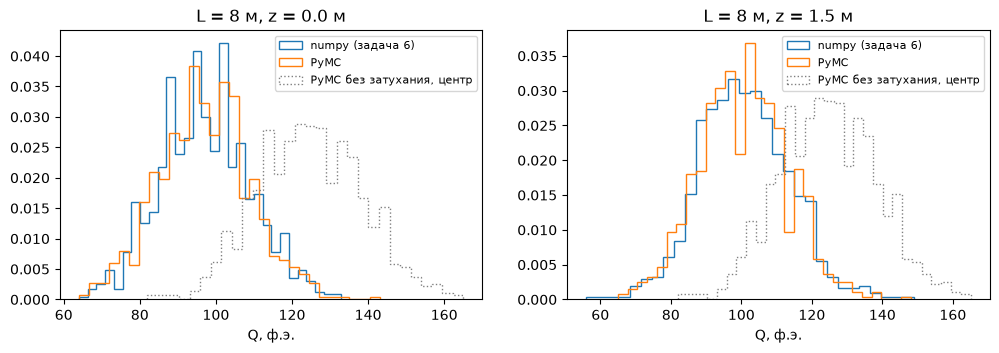

In [7]:
det_att = Detector(R=2.0, N=40, r=0.10, a=0.5, attenuation_length=8.0, rng=11)
res = {}
for z in (0.0, 1.5):
    o = (0, 0, z)
    Q_pm_att = sample_Q(photon_model(det_att, Y, E, o, attenuation=True), n_events, seed=11)['Q']
    Q_np_att = simulate_charge(det_att, Source(Y=Y, rng=110), E, origin=o, n_events=n_events).sum(axis=1)
    Q_ex = det_att.a * Y * E * expected_fraction(det_att, o).sum()
    res[z] = (Q_pm_att, Q_np_att)
    print(f"z = {z} м:  PyMC <Q> = {Q_pm_att.mean():6.2f} ± {Q_pm_att.std()/np.sqrt(n_events):.2f} (σ = {Q_pm_att.std():.2f}),"
          f"  numpy <Q> = {Q_np_att.mean():6.2f} ± {Q_np_att.std()/np.sqrt(n_events):.2f} (σ = {Q_np_att.std():.2f}),"
          f"  ожидание {Q_ex:.2f},  KS p = {stats.ks_2samp(Q_pm_att, Q_np_att).pvalue:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a_, z in zip(ax, res):
    a_.hist(res[z][1], bins=30, histtype='step', density=True, label='numpy (задача 6)')
    a_.hist(res[z][0], bins=30, histtype='step', density=True, label='PyMC')
    a_.hist(Q_pm, bins=30, histtype='step', density=True, ls=':', color='gray', label='PyMC без затухания, центр')
    a_.set_title(f'L = 8 м, z = {z} м'); a_.set_xlabel('Q, ф.э.'); a_.legend(fontsize=8)
plt.show()

**Выводы.**
- Модель задач 1–3 переписана как граф PyMC: те же формулы, `np.*` → `pt.*`, случайные величины — узлы `pm.Poisson`/`pm.Uniform`, промежуточные — `pm.Deterministic`. Переменное число фотонов учитывается маской поверх массива фиксированной длины $n_{max}$.
- Отклик (1000 событий, 1 МэВ, центр): PyMC $\langle Q\rangle = 124.7 \pm 0.4$, $\sigma = 13.7$; numpy (задача 4) $124.7 \pm 0.4$, $\sigma = 13.1$; ожидание $125.1$ и $13.6$. Средние совпадают, KS-тест $p = 0.61$ — распределения согласуются. Совпадают и средние заряды по отдельным каналам.
- Компактная мультиномиальная модель даёт то же распределение ($125.1 \pm 0.4$, KS $p = 0.72$) в ~15 раз быстрее пофотонной: вместо $2\cdot10^4$ переменных — один узел `Multinomial`.
- С затуханием $L = 8$ м PyMC и numpy (задача 6) согласуются в центре ($97.0 \pm 0.4$ против $97.1 \pm 0.4$, ожидание 97.6, KS $p = 1.0$) и при $z = 1.5$ м ($100.5$ против $100.8$, ожидание 101.1, KS $p = 0.91$).
- Для прямого моделирования MCMC не нужна: граф ациклический, и `sample_prior_predictive` разыгрывает независимые события по порядку узлов. Преимущество PyMC-модели проявится в обратной задаче: подставив наблюдённые заряды как `observed`, можно восстанавливать $E$ и вершину. Для NUTS, однако, нужна дифференцируемая модель — дискретные `n_gamma`, `hits` и проверка попадания на катод градиента не имеют, так что для вывода удобнее компактная модель с непрерывным правдоподобием.